# 2 - MLP Classifier Limitations for Image Generation

Dataset: **Fashion-MNIST**  
Model: **784 → 256 → 64 → 10**


In [10]:
import os
import random
import json

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split, TensorDataset
from torchvision import datasets, transforms
from skimage.metrics import structural_similarity

In [11]:
# 1. Prepare Fashion-MNIST
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


transform = transforms.ToTensor()

full_train_data = datasets.FashionMNIST(
    root="data", train=True, download=True, transform=transform
)
test_data = datasets.FashionMNIST(
    root="data", train=False, download=True, transform=transform
)

train_size = 54000
val_size = 6000

train_data, val_data = random_split(
    full_train_data,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
val_loader = DataLoader(val_data, batch_size=128, shuffle=False)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

Using device: cpu


In [12]:
# 2. Create the MLP Classifier
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def get_latent(self, images):
        images = images.view(images.size(0), 784)
        x = torch.relu(self.fc1(images))
        x = torch.relu(self.fc2(x))
        return x

    def forward(self, images):
        x = self.get_latent(images)
        return self.fc3(x)


class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(64, 256)
        self.fc2 = nn.Linear(256, 784)

    def forward(self, latent):
        x = torch.relu(self.fc1(latent))
        x = torch.sigmoid(self.fc2(x))
        return x.view(-1, 1, 28, 28)


class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )
        self.decoder = Decoder()

    def forward(self, images):
        latent = self.encoder(images)
        return self.decoder(latent)

In [13]:
# Helper: Display a group of images
def show_images(images, title, columns=8):
    images = images.detach().cpu()
    rows = (len(images) + columns - 1) // columns

    fig, axes = plt.subplots(rows, columns, figsize=(12, 2 * rows))
    axes = np.array(axes).reshape(-1)

    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < len(images):
            ax.imshow(images[i].squeeze(), cmap="gray", vmin=0, vmax=1)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


In [14]:
# Stage 1: Train the MLP Classifier
model = MLPClassifier().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_function = nn.CrossEntropyLoss()

epochs = 20

for epoch in range(epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        predictions = model(images)
        loss = loss_function(predictions, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += (predictions.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_accuracy = correct / total

    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            predictions = model(images)
            val_correct += (predictions.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = val_correct / val_total

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {total_loss / len(train_loader):.4f} | "
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

# Evaluate using the separate test dataset.
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        predictions = model(images)

        test_correct += (predictions.argmax(1) == labels).sum().item()
        test_total += labels.size(0)

test_accuracy = test_correct / test_total
print("\nStage 1 Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Required accuracy: 88%")



Epoch 1/20 | Loss: 0.6039 | Train Accuracy: 0.7882 | Validation Accuracy: 0.8485
Epoch 2/20 | Loss: 0.4079 | Train Accuracy: 0.8547 | Validation Accuracy: 0.8567
Epoch 3/20 | Loss: 0.3591 | Train Accuracy: 0.8690 | Validation Accuracy: 0.8565
Epoch 4/20 | Loss: 0.3335 | Train Accuracy: 0.8785 | Validation Accuracy: 0.8710
Epoch 5/20 | Loss: 0.3140 | Train Accuracy: 0.8844 | Validation Accuracy: 0.8765
Epoch 6/20 | Loss: 0.2949 | Train Accuracy: 0.8920 | Validation Accuracy: 0.8700
Epoch 7/20 | Loss: 0.2792 | Train Accuracy: 0.8966 | Validation Accuracy: 0.8765
Epoch 8/20 | Loss: 0.2727 | Train Accuracy: 0.8988 | Validation Accuracy: 0.8770
Epoch 9/20 | Loss: 0.2615 | Train Accuracy: 0.9038 | Validation Accuracy: 0.8840
Epoch 10/20 | Loss: 0.2492 | Train Accuracy: 0.9070 | Validation Accuracy: 0.8837
Epoch 11/20 | Loss: 0.2414 | Train Accuracy: 0.9095 | Validation Accuracy: 0.8873
Epoch 12/20 | Loss: 0.2300 | Train Accuracy: 0.9142 | Validation Accuracy: 0.8930
Epoch 13/20 | Loss: 0.223

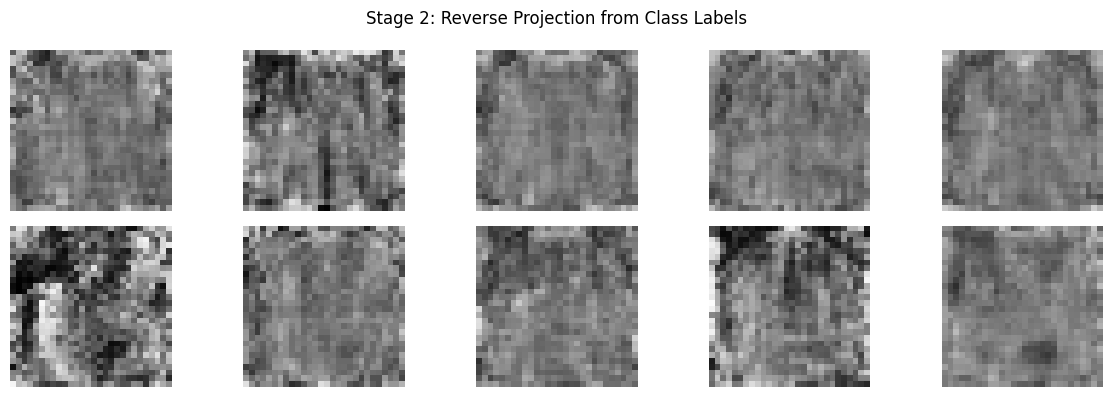

In [15]:
# Stage 2: Reverse Projection from Class Labels
one_hot = torch.eye(10).to(device)

with torch.no_grad():
    x = torch.relu(one_hot @ model.fc3.weight)
    x = torch.relu(x @ model.fc2.weight)
    x = torch.sigmoid(x @ model.fc1.weight)
    generated_from_classes = x.view(-1, 1, 28, 28)

show_images(
    generated_from_classes,
    "Stage 2: Reverse Projection from Class Labels",
    columns=5
)

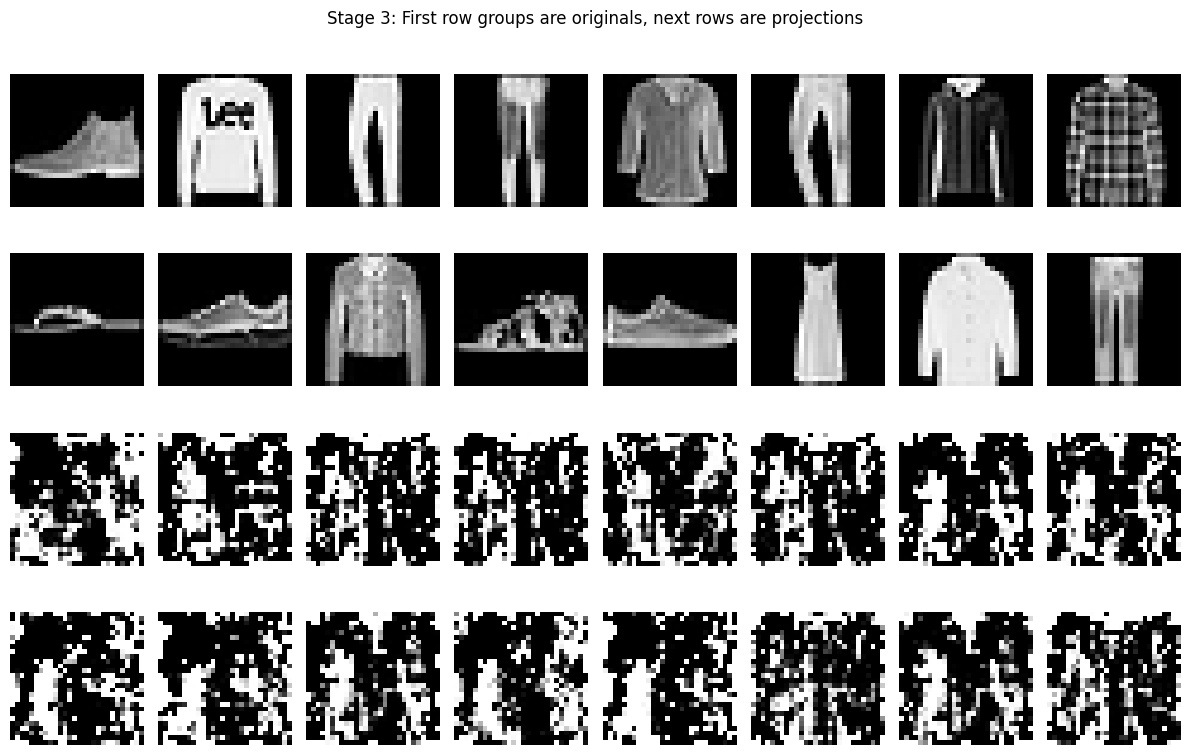

In [16]:
# Stage 3: Reverse Projection from Latent Features
images, labels = next(iter(test_loader))
images = images[:16].to(device)

with torch.no_grad():
    latent = model.get_latent(images)

    x = torch.relu(latent @ model.fc2.weight)
    x = torch.sigmoid(x @ model.fc1.weight)
    reconstructed = x.view(-1, 1, 28, 28)

comparison = torch.cat([images, reconstructed], dim=0)

show_images(
    comparison,
    "Stage 3: First row groups are originals, next rows are projections",
    columns=8
)

Frozen Decoder Epoch 1/15 | MSE: 0.03643
Frozen Decoder Epoch 2/15 | MSE: 0.02500
Frozen Decoder Epoch 3/15 | MSE: 0.02261
Frozen Decoder Epoch 4/15 | MSE: 0.02129
Frozen Decoder Epoch 5/15 | MSE: 0.02047
Frozen Decoder Epoch 6/15 | MSE: 0.01988
Frozen Decoder Epoch 7/15 | MSE: 0.01944
Frozen Decoder Epoch 8/15 | MSE: 0.01908
Frozen Decoder Epoch 9/15 | MSE: 0.01878
Frozen Decoder Epoch 10/15 | MSE: 0.01856
Frozen Decoder Epoch 11/15 | MSE: 0.01833
Frozen Decoder Epoch 12/15 | MSE: 0.01811
Frozen Decoder Epoch 13/15 | MSE: 0.01798
Frozen Decoder Epoch 14/15 | MSE: 0.01783
Frozen Decoder Epoch 15/15 | MSE: 0.01770
Autoencoder Epoch 1/15 | MSE: 0.03559
Autoencoder Epoch 2/15 | MSE: 0.01760
Autoencoder Epoch 3/15 | MSE: 0.01495
Autoencoder Epoch 4/15 | MSE: 0.01354
Autoencoder Epoch 5/15 | MSE: 0.01254
Autoencoder Epoch 6/15 | MSE: 0.01179
Autoencoder Epoch 7/15 | MSE: 0.01119
Autoencoder Epoch 8/15 | MSE: 0.01071
Autoencoder Epoch 9/15 | MSE: 0.01034
Autoencoder Epoch 10/15 | MSE: 0.0100

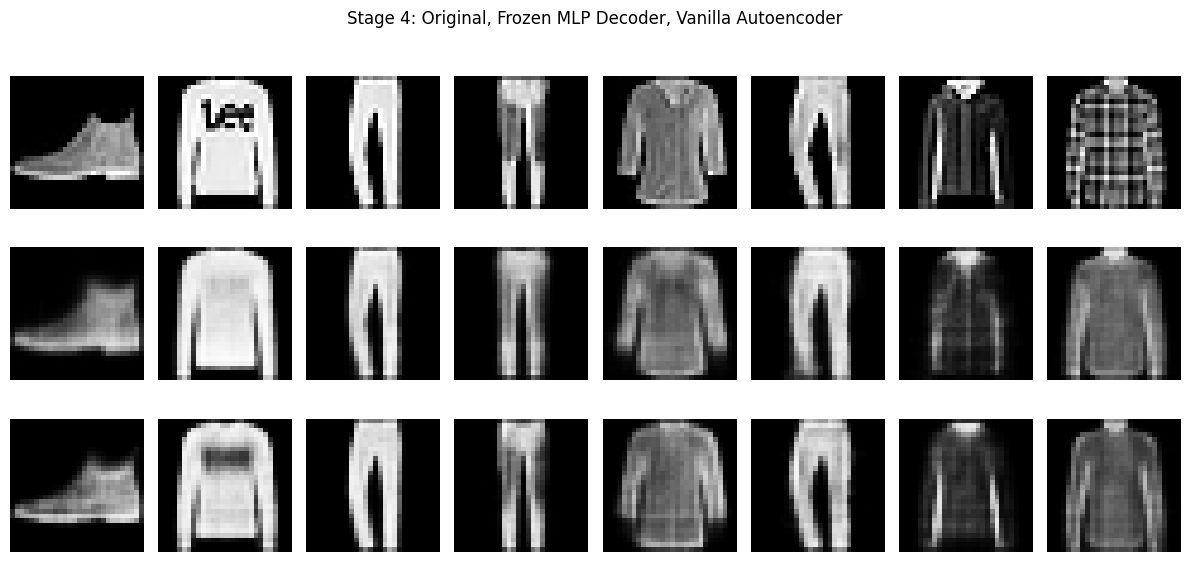

In [17]:
# Stage 4: Frozen Latent Decoder vs Vanilla Autoencoder
for parameter in model.parameters():
    parameter.requires_grad = False

train_latents = []
train_images = []

with torch.no_grad():
    for images, labels in train_loader:
        images = images.to(device)
        latent = model.get_latent(images)

        train_latents.append(latent.cpu())
        train_images.append(images.cpu())

train_latents = torch.cat(train_latents)
train_images = torch.cat(train_images)

latent_dataset = TensorDataset(train_latents, train_images)
latent_loader = DataLoader(latent_dataset, batch_size=128, shuffle=True)

frozen_decoder = Decoder().to(device)
decoder_optimizer = torch.optim.Adam(frozen_decoder.parameters(), lr=0.001)
mse_loss = nn.MSELoss()

for epoch in range(15):
    frozen_decoder.train()
    total_loss = 0

    for latent, original_images in latent_loader:
        latent = latent.to(device)
        original_images = original_images.to(device)

        reconstructed = frozen_decoder(latent)
        loss = mse_loss(reconstructed, original_images)

        decoder_optimizer.zero_grad()
        loss.backward()
        decoder_optimizer.step()

        total_loss += loss.item()

    print(
        f"Frozen Decoder Epoch {epoch + 1}/15 | "
        f"MSE: {total_loss / len(latent_loader):.5f}"
    )

# Train a normal Autoencoder for comparison.
autoencoder = Autoencoder().to(device)
ae_optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)

for epoch in range(15):
    autoencoder.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)

        reconstructed = autoencoder(images)
        loss = mse_loss(reconstructed, images)

        ae_optimizer.zero_grad()
        loss.backward()
        ae_optimizer.step()

        total_loss += loss.item()

    print(
        f"Autoencoder Epoch {epoch + 1}/15 | "
        f"MSE: {total_loss / len(train_loader):.5f}"
    )


# Evaluate reconstruction quality on the test images.
def evaluate_reconstruction(use_autoencoder):
    all_mse = []
    all_psnr = []
    all_ssim = []

    if use_autoencoder:
        autoencoder.eval()
    else:
        model.eval()
        frozen_decoder.eval()

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)

            if use_autoencoder:
                reconstructed = autoencoder(images)
            else:
                latent = model.get_latent(images)
                reconstructed = frozen_decoder(latent)

            reconstructed = reconstructed.clamp(0, 1)

            for i in range(images.size(0)):
                original = images[i, 0].cpu().numpy()
                result = reconstructed[i, 0].cpu().numpy()

                mse = np.mean((original - result) ** 2)
                psnr = 10 * np.log10(1.0 / (mse + 1e-10))
                ssim = structural_similarity(
                    original, result, data_range=1.0
                )

                all_mse.append(mse)
                all_psnr.append(psnr)
                all_ssim.append(ssim)

    return {
        "MSE": float(np.mean(all_mse)),
        "PSNR": float(np.mean(all_psnr)),
        "SSIM": float(np.mean(all_ssim))
    }


frozen_metrics = evaluate_reconstruction(False)
ae_metrics = evaluate_reconstruction(True)

stage4_results = {
    "Frozen MLP Decoder": frozen_metrics,
    "Vanilla Autoencoder": ae_metrics
}

print("\nStage 4 Results:")
print(json.dumps(stage4_results, indent=4))


# Save a visual comparison using the same test images.
images, labels = next(iter(test_loader))
images = images[:8].to(device)

with torch.no_grad():
    latent = model.get_latent(images)
    frozen_result = frozen_decoder(latent)
    ae_result = autoencoder(images)

comparison = torch.cat([images, frozen_result, ae_result], dim=0)

show_images(
    comparison,
    "Stage 4: Original, Frozen MLP Decoder, Vanilla Autoencoder",
    columns=8
)


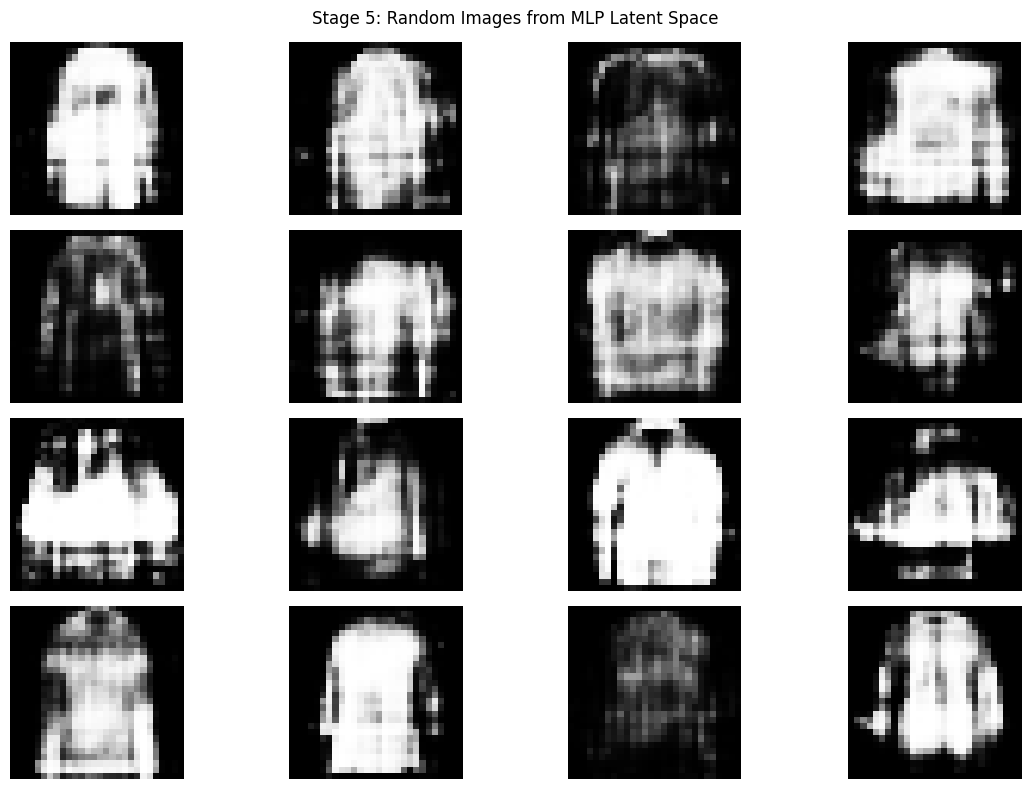

In [19]:
# Stage 5: Random Sampling in the Latent Space
mean = train_latents.mean(dim=0)
std = train_latents.std(dim=0).clamp(min=0.000001)

random_latents = mean + std * torch.randn(16, 64)

with torch.no_grad():
    generated_images = frozen_decoder(random_latents.to(device))

show_images(
    generated_images,
    "Stage 5: Random Images from MLP Latent Space",
    columns=4
)


